# Prosperity 4 — Market Making Strategy Backtest

Compares three strategies on any Prosperity price + trades CSV pair:

| Strategy | Paper |
|---|---|
| **Naive** | Baseline — 1 tick inside bot spread, symmetric |
| **AS-Adaptive** | Avellaneda & Stoikov (2008) + Cartea et al. (2017): rolling σ², live κ, OFI |
| **Abernethy-Kale** | Spread-ladder + weighted majority online learning (NeurIPS 2013) |

**Data used:** both `prices_round_0_day_*.csv` *and* `trades_round_0_day_*.csv`.  
The trades files provide:
- Empirical **κ** (order arrival rate) — more accurate than spread-derived estimate
- **Trade-direction OFI** — cleaner signal than book depth imbalance
- **Event-driven fill model** — bot trade events trigger our passive fills instead of probability


## 1 · Configuration

In [5]:
import os

CONFIG = {
    # Pairs of (prices_file, trades_file) — one pair per trading day
    "days": [
        {
            "prices": "prices_round_0_day_-1.csv",
            "trades": "trades_round_0_day_-1.csv",
        },
        {
            "prices": "prices_round_0_day_-2.csv",
            "trades": "trades_round_0_day_-2.csv",
        },
    ],
    "data_dir": ".",   # folder containing the CSVs

    # Products to analyse (must match 'product' / 'symbol' columns)
    "products": ["EMERALDS", "TOMATOES"],

    # Per-product position limits
    "position_limits": {"EMERALDS": 80, "TOMATOES": 80},

    # Fixed fair value (None = estimate live via EMA of mid-price)
    "fixed_fair": {"EMERALDS": 10_000, "TOMATOES": None},

    # A-S risk-aversion γ per product
    "gamma": {"EMERALDS": 0.05, "TOMATOES": 0.04},

    # EMA smoothing for fair-value estimate
    "ema_alpha": 0.25,

    # Rolling window for σ² and κ estimation
    "vol_window":    50,
    "kappa_window":  100,   # number of inter-trade gaps to average

    # OFI: weight of trade-direction signal on reservation price
    "ofi_weight": 0.30,

    # Passive quote size per level
    "quote_qty": 20,

    # Abernethy-Kale spread ladder
    "ak_spreads": [1, 2, 3, 4, 5, 7],
    "ak_eta":     0.02,
}
print("Config loaded")
print(f"  Products : {CONFIG['products']}")
print(f"  Days     : {len(CONFIG['days'])}")


Config loaded
  Products : ['EMERALDS', 'TOMATOES']
  Days     : 2


## 2 · Imports

In [6]:
import csv, math, statistics, os
from dataclasses import dataclass, field
from typing import List, Dict, Callable

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline
plt.rcParams.update({"figure.dpi": 130, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})
print("Imports OK")


Imports OK


## 3 · Data structures

In [7]:
@dataclass
class Snap:
    ts:      int
    product: str
    bid1: float; bvol1: int
    bid2: float; bvol2: int
    ask1: float; avol1: int
    ask2: float; avol2: int
    mid:  float

    @property
    def bot_half_spread(self) -> float:
        return (self.ask1 - self.bid1) / 2.0


@dataclass
class TradeEvent:
    """A bot-to-bot trade from the trades CSV."""
    ts:        int
    product:   str
    price:     float
    qty:       int
    at_ask:    bool   # True = buy aggressor hit the ask; False = sell aggressor hit the bid


@dataclass
class Fill:
    ts:      int
    price:   float
    qty:     int      # positive = bought, negative = sold
    passive: bool


@dataclass
class Result:
    name:    str
    product: str
    pnl:     List[float] = field(default_factory=list)
    pos:     List[int]   = field(default_factory=list)
    fills:   List[Fill]  = field(default_factory=list)

    def total_pnl(self):  return self.pnl[-1] if self.pnl else 0.0
    def max_pos(self):    return max((abs(p) for p in self.pos), default=0)
    def n_trades(self):   return len(self.fills)
    def sharpe(self):
        diffs = [self.pnl[i] - self.pnl[i-1] for i in range(1, len(self.pnl))]
        if len(diffs) < 2: return 0.0
        mu = sum(diffs) / len(diffs)
        sd = statistics.stdev(diffs)
        return (mu / sd) * math.sqrt(len(diffs)) if sd > 0 else 0.0

print("Data structures defined")


Data structures defined


## 4 · Data loader
Loads both prices **and** trades CSVs and merges them into a single timeline per product.

In [8]:
def load_prices(product: str, path: str) -> List[Snap]:
    snaps = []
    with open(path) as f:
        for row in csv.DictReader(f, delimiter=";"):
            if row["product"] != product or not row["bid_price_1"]:
                continue
            fv = lambda k: float(row[k]) if row.get(k) else 0.0
            iv = lambda k: int(float(row[k])) if row.get(k) else 0
            snaps.append(Snap(
                ts=int(row["timestamp"]), product=product,
                bid1=fv("bid_price_1"), bvol1=iv("bid_volume_1"),
                bid2=fv("bid_price_2"), bvol2=iv("bid_volume_2"),
                ask1=fv("ask_price_1"), avol1=iv("ask_volume_1"),
                ask2=fv("ask_price_2"), avol2=iv("ask_volume_2"),
                mid=fv("mid_price"),
            ))
    return snaps


def load_trades(product: str, path: str, snap_index: Dict[int, Snap]) -> List[TradeEvent]:
    """
    Load trade events and classify direction by comparing trade price
    to the concurrent order book (at_ask = buy aggressor, else sell aggressor).
    """
    events = []
    sorted_tss = sorted(snap_index.keys())

    with open(path) as f:
        for row in csv.DictReader(f, delimiter=";"):
            if row["symbol"] != product:
                continue
            ts  = int(row["timestamp"])
            px  = float(row["price"])
            qty = int(row["quantity"])

            # Find nearest price snapshot to determine direction
            idx = min(range(len(sorted_tss)),
                      key=lambda i: abs(sorted_tss[i] - ts))
            snap = snap_index[sorted_tss[idx]]
            at_ask = px >= snap.ask1
            events.append(TradeEvent(ts=ts, product=product,
                                     price=px, qty=qty, at_ask=at_ask))
    return events


def load_all(product: str, cfg: dict):
    """Load and merge all days of price + trade data for one product."""
    all_snaps  = []
    all_events = []
    for day in cfg["days"]:
        p_path = os.path.join(cfg["data_dir"], day["prices"])
        t_path = os.path.join(cfg["data_dir"], day["trades"])
        snaps  = load_prices(product, p_path)
        idx    = {s.ts: s for s in snaps}
        events = load_trades(product, t_path, idx) if os.path.exists(t_path) else []
        all_snaps.extend(snaps)
        all_events.extend(events)
    return all_snaps, all_events


# Preview
for prod in CONFIG["products"]:
    snaps, events = load_all(prod, CONFIG)
    buys  = sum(1 for e in events if e.at_ask)
    sells = sum(1 for e in events if not e.at_ask)
    print(f"{prod}: {len(snaps):,} price snaps | {len(events):,} trade events "
          f"({buys} buy / {sells} sell)  OFI={((buys-sells)/(buys+sells)):.3f}")


EMERALDS: 20,000 price snaps | 399 trade events (195 buy / 204 sell)  OFI=-0.023
TOMATOES: 20,000 price snaps | 820 trade events (387 buy / 433 sell)  OFI=-0.056


## 5 · Fill engine
Two improvements over a naive probability model:
- **Aggressive fills** as before (our quote crosses the bot best price)
- **Event-driven passive fills**: when a real bot trade event fires at price P,
  our resting quote at the same or better price gets filled — no random coin flip


In [9]:
def build_trade_index(events: List[TradeEvent]) -> Dict[int, List[TradeEvent]]:
    """Group trade events by timestamp for O(1) lookup during simulation."""
    idx: Dict[int, List[TradeEvent]] = {}
    for e in events:
        idx.setdefault(e.ts, []).append(e)
    return idx


def simulate_fills(snap: Snap, our_bid: float, our_ask: float,
                   position: int, quote_qty: int, pos_limit: int,
                   nearby_events: List[TradeEvent]) -> List[Fill]:
    fills, pos = [], position

    # ── Aggressive: our quote crosses the bot book ─────────────────────────
    if our_bid >= snap.ask1 and pos < pos_limit:
        qty = min(quote_qty, snap.avol1, pos_limit - pos)
        if qty > 0:
            fills.append(Fill(snap.ts, snap.ask1, qty, passive=False))
            pos += qty

    if our_ask <= snap.bid1 and pos > -pos_limit:
        qty = min(quote_qty, snap.bvol1, pos + pos_limit)
        if qty > 0:
            fills.append(Fill(snap.ts, snap.bid1, -qty, passive=False))
            pos -= qty

    # ── Event-driven passive fills ─────────────────────────────────────────
    # A bot trade at the ask (buy aggressor) means our ask <= trade_price fills
    # A bot trade at the bid (sell aggressor) means our bid >= trade_price fills
    for ev in nearby_events:
        if ev.at_ask and our_ask <= ev.price and pos > -pos_limit:
            qty = min(quote_qty, pos + pos_limit)
            if qty > 0:
                fills.append(Fill(snap.ts, our_ask, -qty, passive=True))
                pos -= qty

        if not ev.at_ask and our_bid >= ev.price and pos < pos_limit:
            qty = min(quote_qty, pos_limit - pos)
            if qty > 0:
                fills.append(Fill(snap.ts, our_bid, qty, passive=True))
                pos += qty

    return fills


def run_strategy(snaps: List[Snap], events: List[TradeEvent],
                 strategy_fn: Callable, name: str, cfg: dict) -> Result:
    product   = snaps[0].product
    pos_limit = cfg["position_limits"].get(product, 20)
    quote_qty = cfg["quote_qty"]

    result  = Result(name=name, product=product)
    state   = {}
    cash, pos = 0.0, 0

    # Pre-compute trade-direction OFI rolling window and kappa
    # These are passed into state so strategies can read them
    evt_idx = build_trade_index(events)

    # Map each snap timestamp to the nearest trade events within ±500 ticks
    snap_events: Dict[int, List[TradeEvent]] = {s.ts: [] for s in snaps}
    e_sorted = sorted(events, key=lambda e: e.ts)
    ei = 0
    for snap in snaps:
        while ei < len(e_sorted) and e_sorted[ei].ts < snap.ts - 500:
            ei += 1
        j = ei
        while j < len(e_sorted) and e_sorted[j].ts <= snap.ts + 500:
            snap_events[snap.ts].append(e_sorted[j])
            j += 1

    for snap in snaps:
        our_bid, our_ask = strategy_fn(snap, pos, state, cfg,
                                       snap_events[snap.ts])
        if our_bid >= our_ask:
            our_ask = our_bid + 1

        for f in simulate_fills(snap, our_bid, our_ask, pos,
                                 quote_qty, pos_limit, snap_events[snap.ts]):
            cash -= f.price * f.qty
            pos  += f.qty
            result.fills.append(f)

        result.pnl.append(cash + pos * snap.mid)
        result.pos.append(pos)

    return result

print("Fill engine defined")


Fill engine defined


## 6 · Strategies
Each strategy: `(snap, position, state, config, nearby_events) → (bid, ask)`

In [10]:
# ── Shared helpers ─────────────────────────────────────────────────────────────

def get_fair(snap, state, cfg):
    fixed = cfg["fixed_fair"].get(snap.product)
    if fixed is not None:
        return float(fixed)
    alpha = cfg["ema_alpha"]
    prev  = state.get("ema", snap.mid)
    fair  = alpha * snap.mid + (1 - alpha) * prev
    state["ema"] = fair
    return fair


def rolling_sigma2(snap, state, cfg):
    hist = state.setdefault("mids", [])
    hist.append(snap.mid)
    win = cfg["vol_window"] + 1
    if len(hist) > win: del hist[:-win]
    if len(hist) >= 2:
        ch = [hist[i+1] - hist[i] for i in range(len(hist)-1)]
        mu = sum(ch) / len(ch)
        return max(sum((c - mu)**2 for c in ch) / len(ch), 0.25)
    seeds = {"EMERALDS": 1.03, "TOMATOES": 1.89}
    return seeds.get(snap.product, 1.5)


def rolling_kappa(snap, state, cfg, events):
    """
    Estimate κ from real inter-trade arrival times (not from the bot spread).
    κ ≈ 1 / mean_inter_trade_gap  (in units of price-snapshot steps = 100 ticks)
    Falls back to spread-derived estimate while the window fills.
    """
    gaps = state.setdefault("trade_gaps", [])
    last = state.get("last_trade_ts", None)
    for ev in events:
        if last is not None:
            gap = (ev.ts - last) / 100.0   # convert ticks → price-row steps
            if gap > 0:
                gaps.append(gap)
        last = ev.ts
    state["last_trade_ts"] = last
    win = cfg["kappa_window"]
    if len(gaps) > win: del gaps[:-win]

    if gaps:
        mean_gap = sum(gaps) / len(gaps)
        return max(0.1, min(1.0 / mean_gap, 3.0))
    # fallback: spread-derived
    hbs = snap.bot_half_spread
    return max(0.3, min(math.log(2) / hbs if hbs > 0 else 1.5, 3.0))


def trade_ofi(events: List[TradeEvent], state: dict, cfg: dict) -> float:
    """
    Rolling OFI from real trade events: fraction of recent bot trades
    that were buy-side aggressors (hit the ask) vs sell-side (hit the bid).
    Much cleaner than book-depth OFI which bots can spoof.
    """
    buf = state.setdefault("ofi_buf", [])
    for ev in events:
        buf.append(1.0 if ev.at_ask else -1.0)
    win = cfg.get("ofi_window", 30)
    if len(buf) > win: del buf[:-win]
    return sum(buf) / len(buf) if buf else 0.0


# ── 1. Naive ───────────────────────────────────────────────────────────────────
def strategy_naive(snap, pos, state, cfg, events):
    bid = math.floor(snap.bid1 + 1)
    ask = math.ceil (snap.ask1 - 1)
    if bid >= ask:
        bid = math.floor(snap.mid) - 1
        ask = math.ceil (snap.mid) + 1
    return bid, ask


# ── 2. AS-Adaptive ─────────────────────────────────────────────────────────────
def strategy_as_adaptive(snap, pos, state, cfg, events):
    """
    Avellaneda-Stoikov reservation price + optimal spread with:
      - Rolling σ²  from recent mid-price changes
      - Empirical κ from real inter-trade arrival times   <-- new
      - Trade-direction OFI for reservation price tilt    <-- new
    """
    fair  = get_fair(snap, state, cfg)
    s2    = rolling_sigma2(snap, state, cfg)
    kappa = rolling_kappa(snap, state, cfg, events)
    ofi   = trade_ofi(events, state, cfg)
    g     = cfg["gamma"].get(snap.product, 0.05)

    r = fair - pos * g * s2 + cfg["ofi_weight"] * ofi
    h = max(1, min((g * s2 + (2/g) * math.log(1 + g/kappa)) / 2, 5))

    return math.floor(r - h), math.ceil(r + h)


# ── 3. Abernethy-Kale ──────────────────────────────────────────────────────────
def strategy_abernethy_kale(snap, pos, state, cfg, events):
    """
    Weighted-majority spread ladder (Abernethy & Kale, NeurIPS 2013).
    Spread candidates updated via exponential weights each step.
    Centre is A-S reservation price so inventory is handled.
    κ and OFI now come from real trade data.
    """
    spreads = cfg["ak_spreads"]
    n, eta  = len(spreads), cfg["ak_eta"]
    w       = state.setdefault("weights", [1.0/n]*n)

    fair  = get_fair(snap, state, cfg)
    s2    = rolling_sigma2(snap, state, cfg)
    g     = cfg["gamma"].get(snap.product, 0.05)

    pos_limit   = cfg["position_limits"].get(snap.product, 20)
    inv_penalty = abs(pos) / pos_limit

    gains  = [d * (1.0 - inv_penalty) for d in spreads]
    new_w  = [w[i] * math.exp(eta * gains[i]) for i in range(n)]
    z      = sum(new_w)
    state["weights"] = [x/z for x in new_w]

    chosen = sum(state["weights"][i] * spreads[i] for i in range(n))
    h      = max(1, min(round(chosen), 5))
    r      = fair - pos * g * s2 + cfg["ofi_weight"] * trade_ofi(events, state, cfg)

    return math.floor(r - h), math.ceil(r + h)


STRATEGIES = [
    ("Naive",          strategy_naive),
    ("AS-Adaptive",    strategy_as_adaptive),
    ("Abernethy-Kale", strategy_abernethy_kale),
]
print(f"{len(STRATEGIES)} strategies loaded:")
for name, _ in STRATEGIES:
    print(f"  * {name}")


3 strategies loaded:
  * Naive
  * AS-Adaptive
  * Abernethy-Kale


## 7 · Run backtest

In [11]:
all_results: Dict[str, Dict[str, Result]] = {}

for product in CONFIG["products"]:
    snaps, events = load_all(product, CONFIG)
    if not snaps:
        print(f"No data for {product}, skipping")
        continue

    print(f"\n{'='*64}")
    print(f"  {product}  ({len(snaps):,} price snaps | {len(events):,} trade events)")
    print(f"{'='*64}")
    print(f"  {'Strategy':<22} {'PnL':>12} {'Trades':>8} {'MaxPos':>8} {'Sharpe':>8}")
    print(f"  {'-'*62}")

    all_results[product] = {}
    for name, fn in STRATEGIES:
        res = run_strategy(snaps, events, fn, name, CONFIG)
        all_results[product][name] = res
        print(f"  {name:<22} {res.total_pnl():>12,.1f} "
              f"{res.n_trades():>8,} {res.max_pos():>8} {res.sharpe():>8.3f}")

print("\nDone")



  EMERALDS  (20,000 price snaps | 399 trade events)
  Strategy                        PnL   Trades   MaxPos   Sharpe
  --------------------------------------------------------------
  Naive                     539,200.0    3,936       80   36.632
  AS-Adaptive               368,947.0    3,766       80   30.390
  Abernethy-Kale            369,127.0    3,765       80   30.396

  TOMATOES  (20,000 price snaps | 820 trade events)
  Strategy                        PnL   Trades   MaxPos   Sharpe
  --------------------------------------------------------------
  Naive                     606,640.0    5,662       80   35.068
  AS-Adaptive               495,755.0    5,782       80   32.570
  Abernethy-Kale            519,199.0    5,570       80   33.636

Done


## 8 · Fill type breakdown

In [12]:
print(f"{'Product':<12} {'Strategy':<22} {'Aggressive':>12} {'Passive':>10} {'Total':>8}")
print("-"*70)
for product, results in all_results.items():
    for name, res in results.items():
        agg = sum(1 for f in res.fills if not f.passive)
        pas = sum(1 for f in res.fills if f.passive)
        print(f"{product:<12} {name:<22} {agg:>12,} {pas:>10,} {agg+pas:>8,}")


Product      Strategy                 Aggressive    Passive    Total
----------------------------------------------------------------------
EMERALDS     Naive                             0      3,936    3,936
EMERALDS     AS-Adaptive                      93      3,673    3,766
EMERALDS     Abernethy-Kale                   92      3,673    3,765
TOMATOES     Naive                             0      5,662    5,662
TOMATOES     AS-Adaptive                     343      5,439    5,782
TOMATOES     Abernethy-Kale                  285      5,285    5,570


## 9 · Cumulative PnL

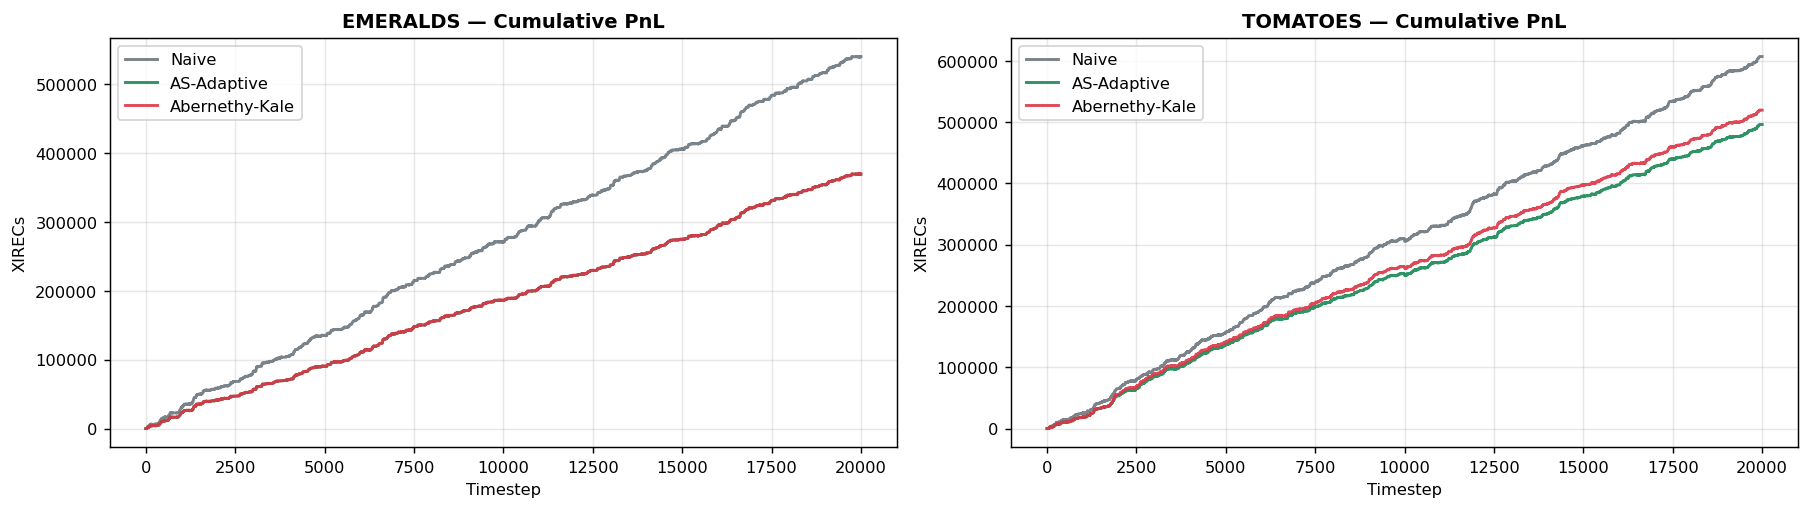

In [13]:
COLORS = {
    "Naive":          "#6c757d",
    "AS-Adaptive":    "#198754",
    "Abernethy-Kale": "#dc3545",
}
n_prod = len(all_results)
fig, axes = plt.subplots(1, n_prod, figsize=(7*n_prod, 4))
if n_prod == 1: axes = [axes]

for ax, (product, results) in zip(axes, all_results.items()):
    for name, res in results.items():
        ax.plot(res.pnl, label=name, color=COLORS.get(name, "blue"),
                linewidth=1.6, alpha=0.9)
    ax.set_title(f"{product} — Cumulative PnL", fontweight="bold")
    ax.set_xlabel("Timestep"); ax.set_ylabel("XIRECs"); ax.legend()
plt.tight_layout(); plt.show()


## 10 · Inventory over time

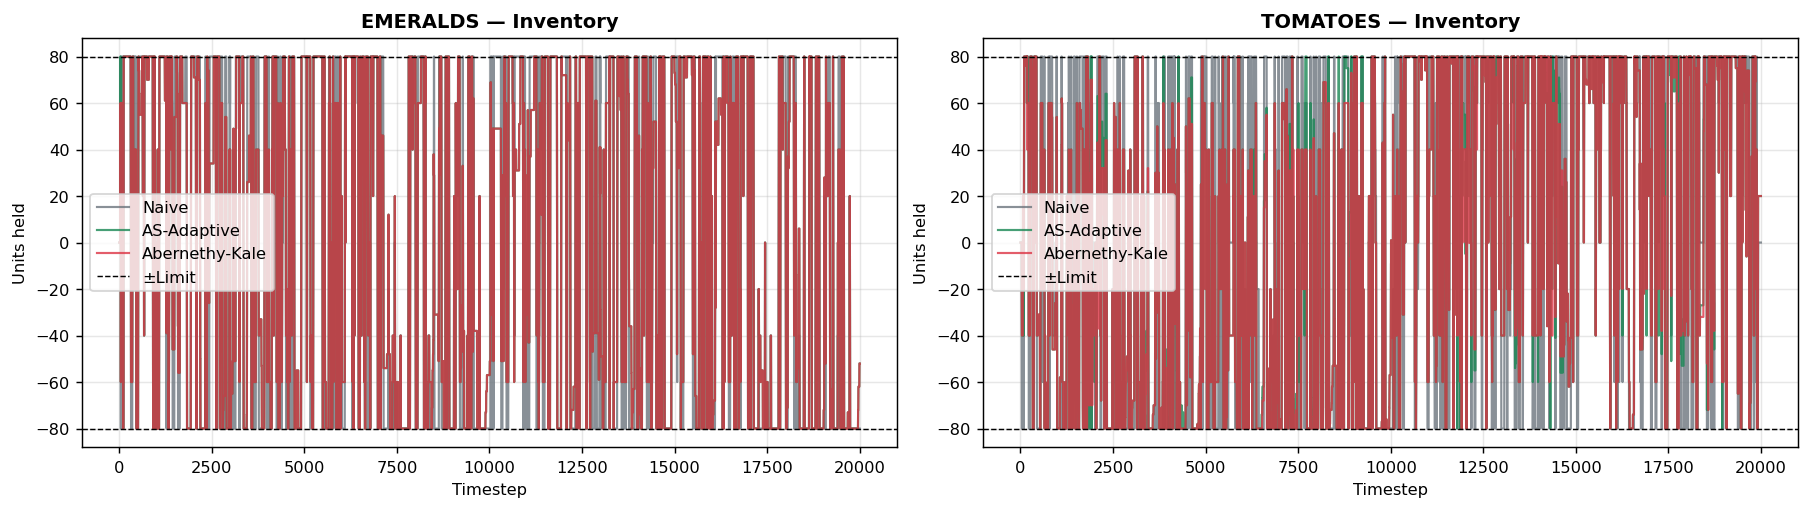

In [14]:
fig, axes = plt.subplots(1, n_prod, figsize=(7*n_prod, 4))
if n_prod == 1: axes = [axes]
for ax, (product, results) in zip(axes, all_results.items()):
    lim = CONFIG["position_limits"].get(product, 20)
    for name, res in results.items():
        ax.plot(res.pos, label=name, color=COLORS.get(name,"blue"),
                linewidth=1.2, alpha=0.8)
    ax.axhline( lim, color="black", ls="--", lw=0.8)
    ax.axhline(-lim, color="black", ls="--", lw=0.8, label="±Limit")
    ax.set_title(f"{product} — Inventory", fontweight="bold")
    ax.set_xlabel("Timestep"); ax.set_ylabel("Units held"); ax.legend()
plt.tight_layout(); plt.show()


## 11 · Summary — Final PnL & Sharpe

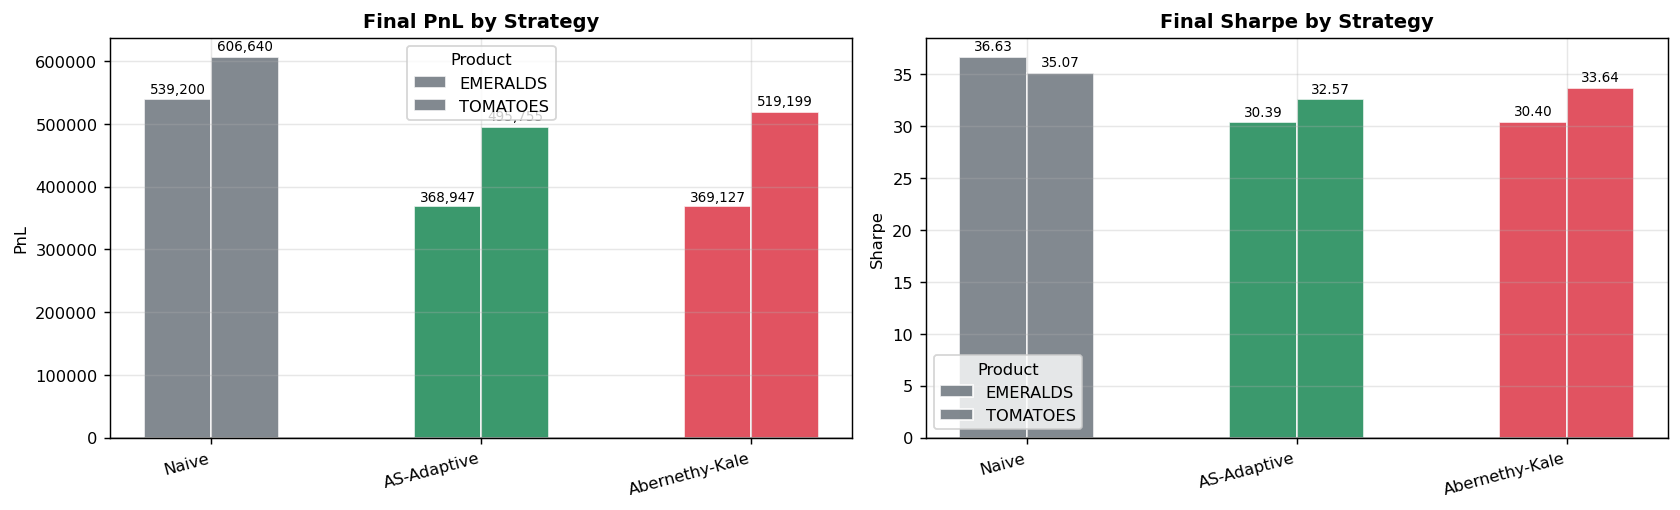

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["PnL", "Sharpe"]):
    n_strat = len(STRATEGIES)
    width   = 0.25
    for i, (product, results) in enumerate(all_results.items()):
        names  = [n for n,_ in STRATEGIES if n in results]
        vals   = ([results[n].total_pnl() for n in names] if metric=="PnL"
                  else [results[n].sharpe() for n in names])
        cols   = [COLORS.get(n,"blue") for n in names]
        offset = (i - (n_prod-1)/2) * width
        bars   = ax.bar([xi + offset for xi in range(len(names))], vals,
                        width=width, label=product, color=cols, alpha=0.85,
                        edgecolor="white")
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() * 1.01,
                    f"{val:,.0f}" if metric=="PnL" else f"{val:.2f}",
                    ha="center", va="bottom", fontsize=7.5)
    ax.set_xticks(range(len(STRATEGIES)))
    ax.set_xticklabels([n for n,_ in STRATEGIES], rotation=15, ha="right")
    ax.set_title(f"Final {metric} by Strategy", fontweight="bold")
    ax.set_ylabel(metric); ax.axhline(0, color="black", lw=0.8)
    if n_prod > 1: ax.legend(title="Product")
plt.tight_layout(); plt.show()


## 12 · Adapting to new rounds

### Plugging in new data
Edit `CONFIG["days"]` at the top — just add one dict per trading day:
```python
{"prices": "prices_round_1_day_1.csv", "trades": "trades_round_1_day_1.csv"},
```
If a round has no trades file, set `"trades": None` and the loader will skip it
(fill model falls back to a spread-position probability).

### Per-product tuning
| Parameter | Effect | Guidance |
|---|---|---|
| `gamma` | Risk-aversion → spread width + reservation skew | Increase if inventory keeps hitting the limit |
| `ofi_weight` | How strongly trade direction tilts reservation price | Increase for trending products |
| `fixed_fair` | Hard-coded fair value | Use only for confirmed mean-reverting products |
| `ak_spreads` | Candidate spreads for Abernethy-Kale | Widen range for more volatile products |

### Which strategy to use?
- **Stable, mean-reverting** (e.g. EMERALDS): Abernethy-Kale converges to the right spread fastest  
- **Trending / drifting** (e.g. TOMATOES): AS-Adaptive — rolling σ² + OFI corrects the centre before inventory accumulates on the wrong side  
- **Unknown new product**: run both and compare the inventory chart — whichever stays near zero is the better fit
